# loc_exp: base data pipeline (identical to final.ipynb)

Import and process the data exactly as `final.ipynb` does -- same source
file, same leakage-column drop, same type-fixing, same six row filters,
same feature engineering -- with nothing added yet. This is a clean
starting point for whatever location experiment comes next in this
notebook, kept separate from `location_factors.ipynb`.

## 1. Import data (identical to final.ipynb)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/dvrs_with_team_external.parquet")
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Loaded 92,010 rows, 56 columns


,valuation_roll_number,valuation_number_assessment,valuation_number_suffix,sale_date,district_code,sale_type,sales_group,sale_tenure,price_value_relationship,sale_price_gross,sale_price_net,sale_price_chattels,sale_price_other,capital_value,land_value,current_effective_valuation_date,situation_number,additional_situation_number,situation_name,certificate_of_title,land_area,zoning,actual_property_use,units_of_use,off_street_parking,building_age_indicator,building_condition_indicator,building_construction_indicator,building_site_coverage,building_total_floor_area,property_category,legal_description,mass_contour,mass_view,mass_scope_of_view,mass_total_floor_area,mass_deck,mass_workshop_laundry,mass_other_improvements,mass_garage_under_main_roof,mass_garage_freestanding,valuation_id_concat,longitude,latitude,in_flood_plain,in_flood_sensitive_area,dist_to_flood_plain_m,dist_to_flood_sensitive_area_m,unitary_plan_zone,linz_matched,walk_supermarket_network_m,walk_bus_stop_network_m,drive_supermarket_network_m,drive_bus_stop_network_m,noise_category_combination,sa2_new_dwellings_consented_12m
0,1,2501710000,NaN,25022026,14,S,701,1,1,1514000,1499000,15000,0,1400000,1025000,45413,166,NaN,Point Chevalier RD,335510,0,9C,91,1,1,192,GG,WI,80,87,RD192A,"Carport 1 DP 384040, Flat 1 DP 384040,",LV,N,N,87,Y,N,N,0,1,1_2501710000,174.706389,-36.865688,False,False,241.910185,4866.407069,60.0,True,1578.192284,54.442135,535.386978,0.000000,outside_current_overlay,20
1,1,2600010100,NaN,1042025,14,S,701,1,1,1515112,1507112,8000,0,1675000,1500000,44348,7,NaN,Montrose ST,NA118D/908,0.0403,9D,91,1,0,193,AA,WT,120,117,RD193B,Lot 2 DP 189123 403m2,LV,N,N,117,Y,N,N,0,0,1_2600010100,174.708779,-36.869417,False,False,194.452135,4614.989420,8.0,True,309.197383,173.432349,134.495189,155.505174,outside_current_overlay,7
2,1,4300000201,NaN,14022025,14,S,701,1,1,1622800,1609800,13000,0,1650000,1360000,44348,5,NaN,St Michaels AV,NA57C/301,0,9C,91,1,1,198,AA,WT,60,124,RD198B,"Flat 3 DP 103999, Lot 4 DP 7475 652m2",LV,N,N,124,Y,N,N,1,0,1_4300000201,174.702890,-36.861304,False,False,199.900952,4667.722058,60.0,True,1720.397633,68.370379,1122.801352,9.608944,outside_current_overlay,3
3,1,4300110000,NaN,17012025,14,S,701,1,1,2105000,2092000,13000,0,2600000,2325000,44348,35,NaN,St Michaels AV,NA405/218,0.0656,9B,91,1,1,193,AA,WT,120,123,RD193B,Lot 2 DP 15494 656m2,EF,N,N,123,Y,N,N,0,0,1_4300110000,174.700846,-36.862339,False,False,18.820703,4814.776819,18.0,True,1981.946279,329.919025,1502.064675,333.383823,outside_current_overlay,11
4,1,4300270001,NaN,11112025,14,S,701,1,2,1875000,1862000,13000,0,2300000,2025000,45413,66,NaN,St Michaels AV,115395,0.0396,9B,91,1,1,192,AA,WI,137,124,RD192B,Lot 1 DP 328302 396m2,EF,W,M,109,Y,N,N,1,0,1_4300270001,174.698847,-36.863616,False,False,6.764028,4804.594688,18.0,True,2224.730646,465.392323,1606.980701,493.788293,outside_current_overlay,9


### 1.1 Remove leakage columns

- `sale_price_net`, `sale_price_chattels`, `sale_price_other`: these add up
  to the target price, so keeping them would be cheating.
- `capital_value`, `land_value`: the council's own valuation, not a real
  property feature. Keeping it would let the model copy an existing price
  estimate instead of learning from the data.

All five are removed before any analysis.

In [3]:
df = df.drop(columns=[
    "sale_price_net", "sale_price_chattels", "sale_price_other",
    "capital_value", "land_value",
])
print(f"Dropped sale_price_net/chattels/other, capital_value, land_value. {df.shape[1]} columns remain.")

Dropped sale_price_net/chattels/other, capital_value, land_value. 51 columns remain.


## 2. Clean up data types (identical to final.ipynb)

In [4]:
def parse_sale_date(s):
    if pd.isna(s):
        return pd.NaT
    s = str(s)
    year = int(s[-4:])
    month = int(s[-6:-4])
    day = int(s[:-6])
    return pd.Timestamp(year=year, month=month, day=day)


df["sale_date_parsed"] = df["sale_date"].apply(parse_sale_date)
df["current_effective_valuation_date_parsed"] = pd.to_datetime(
    pd.to_numeric(df["current_effective_valuation_date"], errors="coerce"), unit="D", origin="1899-12-30"
)

numeric_cols = [
    "sale_price_gross",
    "land_area", "building_total_floor_area",
    "mass_total_floor_area", "building_site_coverage", "off_street_parking",
    "units_of_use", "mass_garage_under_main_roof", "mass_garage_freestanding",
    "longitude", "latitude",
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Team-external numeric columns are already float/Int64, just need a plain float dtype
external_numeric_cols = [
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
    "sa2_new_dwellings_consented_12m",
]
for col in external_numeric_cols:
    df[col] = df[col].astype(float)

# Nullable boolean dtype: rows with no LINZ coordinate match (linz_matched=False)
# have None here, not True/False. Casting to "boolean" (not plain bool/object)
# makes `|` propagate that as NA instead of silently treating it as False.
for col in ["in_flood_plain", "in_flood_sensitive_area"]:
    df[col] = df[col].astype("boolean")

print("sale_date_parsed range:", df["sale_date_parsed"].min().date(), "to", df["sale_date_parsed"].max().date())
df[numeric_cols + external_numeric_cols].describe().T

sale_date_parsed range: 2024-01-01 to 2026-08-21


,count,mean,std,min,25%,50%,75%,max
sale_price_gross,92010.0,2.616173e+06,3.899396e+07,1.000000,755000.000000,1000000.000000,1.450000e+06,1.792507e+09
land_area,92010.0,2.580082e-01,4.050016e+00,0.000000,0.000000,0.028650,6.650000e-02,4.820000e+02
building_total_floor_area,92010.0,2.254900e+02,4.633720e+03,0.000000,86.000000,127.000000,1.850000e+02,3.900000e+05
mass_total_floor_area,92010.0,1.157855e+02,7.865629e+01,0.000000,77.000000,108.000000,1.520000e+02,4.888000e+03
building_site_coverage,92010.0,1.322485e+02,2.103515e+03,0.000000,59.000000,94.000000,1.370000e+02,6.000600e+05
off_street_parking,92010.0,1.570775e+00,7.167405e+00,0.000000,0.000000,1.000000,2.000000e+00,9.800000e+02
units_of_use,92010.0,1.049125e+00,7.697022e-01,0.000000,1.000000,1.000000,1.000000e+00,1.550000e+02
mass_garage_under_main_roof,92010.0,7.599826e-01,9.464774e-01,0.000000,0.000000,0.000000,2.000000e+00,5.600000e+01
mass_garage_freestanding,92010.0,3.416368e-01,6.970015e-01,0.000000,0.000000,0.000000,0.000000e+00,2.000000e+01
longitude,87916.0,1.747796e+02,1.158947e-01,174.234241,174.700457,174.765891,1.748747e+02,1.755077e+02


## 3. Filter to clean, genuine sales (identical six filters to final.ipynb)

In [5]:
df_cv = df.copy()
assert "capital_value" not in df_cv.columns and "land_value" not in df_cv.columns, (
    "capital_value / land_value leaked back into df_cv -- they must stay dropped "
    "from the feature set, same as the rest of this notebook"
)
print("Confirmed: capital_value / land_value are not present in df_cv")

before = len(df_cv)
df_cv = df_cv[df_cv["zoning"].astype(str).str[0].isin(["9", "1", "2"])]
print(f"Residential / rural / lifestyle zoning only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["units_of_use"] == 1]
print(f"Single unit of use only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["sale_tenure"].astype(str) == "1"]
print(f"Freehold sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["sale_type"] == "S"]
print(f"Single-property sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["price_value_relationship"] == "1"]
print(f"Arm's-length market sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["linz_matched"]]
print(f"LINZ-matched coordinate available: {len(df_cv):,} / {before:,} rows kept")

# Sort chronologically -- required for TimeSeriesSplit below, which assumes
# row order IS time order (it does not sort for you).
df_cv = df_cv.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"\nFinal filtered shape: {df_cv.shape}")
print(f"Date range: {df_cv['sale_date_parsed'].min().date()} to {df_cv['sale_date_parsed'].max().date()}")

Confirmed: capital_value / land_value are not present in df_cv
Residential / rural / lifestyle zoning only: 80,070 / 92,010 rows kept
Single unit of use only: 77,370 / 80,070 rows kept
Freehold sales only: 76,395 / 77,370 rows kept
Single-property sales only: 74,112 / 76,395 rows kept
Arm's-length market sales only: 61,244 / 74,112 rows kept
LINZ-matched coordinate available: 59,798 / 61,244 rows kept

Final filtered shape: (59798, 53)
Date range: 2024-01-01 to 2026-08-18


## 4. Feature engineering and feature sets (identical to final.ipynb)

In [6]:
df_cv["property_type"] = df_cv["property_category"].str[0]
df_cv["sale_year"] = df_cv["sale_date_parsed"].dt.year
df_cv["sale_month"] = df_cv["sale_date_parsed"].dt.month
df_cv["sale_quarter"] = df_cv["sale_date_parsed"].dt.quarter
df_cv["has_flood_risk"] = df_cv["in_flood_plain"] | df_cv["in_flood_sensitive_area"]
df_cv["in_noise_overlay"] = df_cv["noise_category_combination"] != "outside_current_overlay"
df_cv["unitary_plan_zone"] = df_cv["unitary_plan_zone"].fillna(-1).astype(int).astype(str)

BASELINE_CAT = [
    "zoning", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "mass_contour", "mass_view", "mass_scope_of_view",
    "mass_deck", "mass_workshop_laundry", "mass_other_improvements",
    "property_type", "actual_property_use",
]
BASELINE_NUM = [
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "building_site_coverage", "off_street_parking",
    "mass_garage_under_main_roof", "mass_garage_freestanding",
    "sale_year", "sale_month", "sale_quarter",
]
BASELINE_BOOL = []

EXTERNAL_CAT = ["unitary_plan_zone", "noise_category_combination"]
EXTERNAL_NUM = [
    "longitude", "latitude", "dist_to_flood_plain_m", "dist_to_flood_sensitive_area_m",
    "sa2_new_dwellings_consented_12m", "walk_supermarket_network_m", "walk_bus_stop_network_m",
]
EXTERNAL_BOOL = ["in_flood_plain", "in_flood_sensitive_area", "has_flood_risk", "in_noise_overlay"]

for col in BASELINE_CAT:
    df_cv[col] = df_cv[col].fillna("Unknown").astype(str)
for col in EXTERNAL_CAT:
    df_cv[col] = df_cv[col].fillna("Unknown").astype(str)

LOG_COLS = [
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "walk_supermarket_network_m", "walk_bus_stop_network_m",
]
for col in LOG_COLS:
    df_cv[col] = np.log1p(df_cv[col])

baseline_cols = BASELINE_CAT + BASELINE_NUM + BASELINE_BOOL
augmented_cols = baseline_cols + EXTERNAL_CAT + EXTERNAL_NUM + EXTERNAL_BOOL
all_cat = BASELINE_CAT + EXTERNAL_CAT
all_num = BASELINE_NUM + EXTERNAL_NUM
all_bool = BASELINE_BOOL + EXTERNAL_BOOL

print(f"Baseline:  {len(baseline_cols)} features")
print(f"Augmented: {len(augmented_cols)} features (+{len(augmented_cols) - len(baseline_cols)} external)")

Baseline:  22 features
Augmented: 35 features (+13 external)


## 5. Ready for the next experiment

`df_cv` is now filtered, sorted chronologically, and feature-engineered,
with `baseline_cols`/`augmented_cols`/`all_cat`/`all_num`/`all_bool`/
`LOG_COLS` all defined exactly as in `final.ipynb`. Nothing modeling- or
experiment-specific has been added yet -- that's the next step.

## 6. XGBoost on external features only -- no property attributes at all

Neither `final.ipynb`'s "baseline" (property only) nor "augmented"
(property + external) model answers this directly: how well can price be
predicted using *only* the 13 external features (location, zoning, flood,
noise, SA2 consents, amenity distance), with zero information about the
property itself (no floor area, no age, no condition)?

Same `TimeSeriesSplit(n_splits=5)` design and fixed XGBoost
hyperparameters as `final.ipynb`, so this is directly comparable to that
notebook's baseline ($317,631 RMSE) and augmented ($214,530 RMSE) pooled
results.

In [7]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBRegressor


def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))


def mae(y, yhat):
    return np.mean(np.abs(y - yhat))


def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100


XGB_PARAMS = dict(n_estimators=500, max_depth=6, learning_rate=0.05,
                   subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)

external_cols = EXTERNAL_CAT + EXTERNAL_NUM + EXTERNAL_BOOL
print(f"Training on {len(external_cols)} external features only (no baseline/property columns): {external_cols}")

kf = TimeSeriesSplit(n_splits=5)
fold_rows = []
oof_rows = []

for fold_i, (train_idx, test_idx) in enumerate(kf.split(df_cv), start=1):
    train_df, test_df = df_cv.iloc[train_idx], df_cv.iloc[test_idx]

    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[EXTERNAL_CAT])

    X_train = train_df[external_cols].copy()
    X_test = test_df[external_cols].copy()
    X_train[EXTERNAL_CAT] = encoder.transform(train_df[EXTERNAL_CAT])
    X_test[EXTERNAL_CAT] = encoder.transform(test_df[EXTERNAL_CAT])
    for col in EXTERNAL_BOOL:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train, X_test = X_train.astype(float), X_test.astype(float)

    nan_cols = [c for c in EXTERNAL_NUM if X_train[c].isna().any() or X_test[c].isna().any()]
    medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(medians)

    for col in LOG_COLS:
        if col in X_train.columns:
            X_train[col] = np.log1p(X_train[col])
            X_test[col] = np.log1p(X_test[col])

    y_train, y_test = train_df["sale_price_gross"].values, test_df["sale_price_gross"].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)
    X_train_f, y_train_f = X_train[train_keep], y_train[train_keep]
    X_test_f, y_test_f = X_test[test_keep], y_test[test_keep]
    test_idx_f = test_idx[test_keep]

    model = XGBRegressor(**XGB_PARAMS)
    model.fit(X_train_f, y_train_f)
    pred = model.predict(X_test_f)

    fold_rows.append({
        "fold": fold_i, "n_test": len(y_test_f),
        "RMSE": rmse(y_test_f, pred), "MAE": mae(y_test_f, pred), "MAPE": mape(y_test_f, pred),
    })
    oof_rows.append(pd.DataFrame({"row_id": test_idx_f, "fold": fold_i, "actual": y_test_f, "pred": pred}))
    print(f"Fold {fold_i}/5: external-only RMSE=${fold_rows[-1]['RMSE']:,.0f}  "
          f"MAE=${fold_rows[-1]['MAE']:,.0f}  MAPE={fold_rows[-1]['MAPE']:.2f}%")

fold_results = pd.DataFrame(fold_rows)
oof = pd.concat(oof_rows, ignore_index=True)
print(f"\nOut-of-fold rows: {len(oof):,}")

Training on 13 external features only (no baseline/property columns): ['unitary_plan_zone', 'noise_category_combination', 'longitude', 'latitude', 'dist_to_flood_plain_m', 'dist_to_flood_sensitive_area_m', 'sa2_new_dwellings_consented_12m', 'walk_supermarket_network_m', 'walk_bus_stop_network_m', 'in_flood_plain', 'in_flood_sensitive_area', 'has_flood_risk', 'in_noise_overlay']
Fold 1/5: external-only RMSE=$400,755  MAE=$269,126  MAPE=25.07%
Fold 2/5: external-only RMSE=$386,304  MAE=$263,044  MAPE=24.26%
Fold 3/5: external-only RMSE=$382,327  MAE=$257,503  MAPE=24.10%
Fold 4/5: external-only RMSE=$379,049  MAE=$254,461  MAPE=23.53%
Fold 5/5: external-only RMSE=$372,283  MAE=$249,795  MAPE=22.97%

Out-of-fold rows: 48,848


### 6.1 Pooled result, compared against final.ipynb's baseline and augmented models

In [8]:
ext_rmse = rmse(oof["actual"], oof["pred"])
ext_mae = mae(oof["actual"], oof["pred"])
ext_mape = mape(oof["actual"], oof["pred"])

# Reference numbers from final.ipynb (same filters, same folds, same hyperparameters)
REF_BASELINE_RMSE, REF_BASELINE_MAE, REF_BASELINE_MAPE = 317631.16, 208318.50, 18.17
REF_AUGMENTED_RMSE, REF_AUGMENTED_MAE, REF_AUGMENTED_MAPE = 214529.56, 131243.38, 11.31

comparison = pd.DataFrame([
    {"model": "Property only (final.ipynb baseline)", "RMSE": REF_BASELINE_RMSE, "MAE": REF_BASELINE_MAE, "MAPE": REF_BASELINE_MAPE},
    {"model": "External only (this section)", "RMSE": ext_rmse, "MAE": ext_mae, "MAPE": ext_mape},
    {"model": "Property + external (final.ipynb augmented)", "RMSE": REF_AUGMENTED_RMSE, "MAE": REF_AUGMENTED_MAE, "MAPE": REF_AUGMENTED_MAPE},
]).set_index("model")
comparison.round(2)

,RMSE,MAE,MAPE
model,,,
Property only (final.ipynb baseline),317631.16,208318.50,18.17
External only (this section),384260.94,258780.87,23.98
Property + external (final.ipynb augmented),214529.56,131243.38,11.31


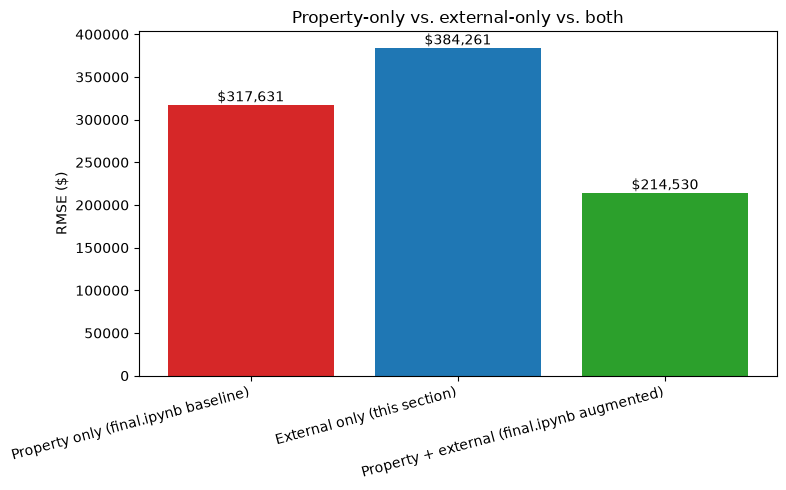

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["tab:red", "tab:blue", "tab:green"]
bars = ax.bar(comparison.index, comparison["RMSE"], color=colors)
for bar, v in zip(bars, comparison["RMSE"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"${v:,.0f}", ha="center", va="bottom")
ax.set_ylabel("RMSE ($)")
ax.set_title("Property-only vs. external-only vs. both")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### 6.2 What this tells us

Fill in after running:

- Is external data alone (no property attributes at all) better or worse
  than property attributes alone? Either answer is informative: if
  external-only is close to or beats property-only, location/context data
  is doing a surprising amount of work on its own; if it's much worse,
  property attributes (size, age, condition) remain the primary driver and
  external data's value is mainly in combination with them, consistent
  with `final.ipynb`'s ablation (the augmented model beats either alone).

## 7. SHAP for the external-only model

The 5-fold loop above only keeps the last fold's model in memory, which
isn't a stable choice for explaining -- refit fresh on a single
chronological 80/20 split (same approach `final.ipynb` section 17 uses),
then run SHAP on a 500-row sample of the test set.

In [10]:
import shap

split_point = int(len(df_cv) * 0.8)
train_df, test_df = df_cv.iloc[:split_point], df_cv.iloc[split_point:]

encoder_ext = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder_ext.fit(train_df[EXTERNAL_CAT])

X_train_ext = train_df[external_cols].copy()
X_test_ext = test_df[external_cols].copy()
X_train_ext[EXTERNAL_CAT] = encoder_ext.transform(train_df[EXTERNAL_CAT])
X_test_ext[EXTERNAL_CAT] = encoder_ext.transform(test_df[EXTERNAL_CAT])
for col in EXTERNAL_BOOL:
    X_train_ext[col] = X_train_ext[col].astype(int)
    X_test_ext[col] = X_test_ext[col].astype(int)
X_train_ext, X_test_ext = X_train_ext.astype(float), X_test_ext.astype(float)

nan_cols_ext = [c for c in EXTERNAL_NUM if X_train_ext[c].isna().any() or X_test_ext[c].isna().any()]
medians_ext = X_train_ext[nan_cols_ext].median()
X_train_ext[nan_cols_ext] = X_train_ext[nan_cols_ext].fillna(medians_ext)
X_test_ext[nan_cols_ext] = X_test_ext[nan_cols_ext].fillna(medians_ext)
for col in LOG_COLS:
    if col in X_train_ext.columns:
        X_train_ext[col] = np.log1p(X_train_ext[col])
        X_test_ext[col] = np.log1p(X_test_ext[col])

y_train_ext = train_df["sale_price_gross"].values
p1e, p99e = np.quantile(y_train_ext, [0.01, 0.99])
train_keep_e = (y_train_ext >= p1e) & (y_train_ext <= p99e)

ext_model = XGBRegressor(**XGB_PARAMS)
ext_model.fit(X_train_ext[train_keep_e], y_train_ext[train_keep_e])

shap_sample_ext = X_test_ext.sample(n=min(500, len(X_test_ext)), random_state=42)
explainer_ext = shap.TreeExplainer(ext_model)
shap_values_ext = explainer_ext.shap_values(shap_sample_ext)

print(f"Model trained on {len(external_cols)} external features, {train_keep_e.sum():,} train rows")

d:\Codes\COMPSCI_760_Group_3_Intelligent_Real_Estate_Price_Prediction_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model trained on 13 external features, 46,889 train rows


### 7.1 Summary plot

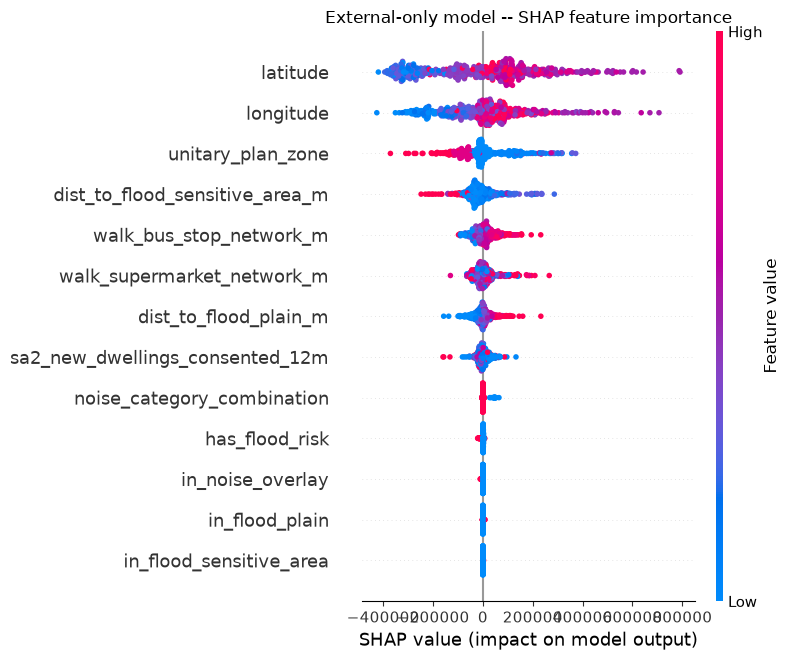

In [11]:
shap.summary_plot(shap_values_ext, shap_sample_ext, max_display=15, show=False)
plt.title("External-only model -- SHAP feature importance")
plt.tight_layout()
plt.show()

### 7.2 Ranked table

In [12]:
mean_abs_shap_ext = pd.Series(np.abs(shap_values_ext).mean(axis=0), index=external_cols)
ext_shap_rank = mean_abs_shap_ext.sort_values(ascending=False)
ext_shap_rank_pct = ext_shap_rank / ext_shap_rank.sum() * 100

pd.DataFrame({"mean_abs_shap": ext_shap_rank.round(0), "% of total": ext_shap_rank_pct.round(1)})

,mean_abs_shap,% of total
latitude,187140.0,34.900002
longitude,121547.0,22.700001
unitary_plan_zone,74517.0,13.900000
dist_to_flood_sensitive_area_m,45095.0,8.400000
walk_bus_stop_network_m,31686.0,5.900000
walk_supermarket_network_m,28390.0,5.300000
dist_to_flood_plain_m,24990.0,4.700000
sa2_new_dwellings_consented_12m,16801.0,3.100000
noise_category_combination,2790.0,0.500000
has_flood_risk,2047.0,0.400000


## 8. External features minus coordinates -- no latitude/longitude at all

Section 7 found `latitude`+`longitude` are 57.6% of the external-only
model's SHAP on their own. This section removes them entirely: can the
remaining 11 "named" external features (zoning, flood, noise, SA2
consents, walking distance) predict price at all without any coordinate,
and which one of them does the model lean on hardest once coordinates
aren't an option?

In [13]:
external_cols_no_coords = [c for c in external_cols if c not in ("longitude", "latitude")]
EXTERNAL_NUM_NC = [c for c in EXTERNAL_NUM if c not in ("longitude", "latitude")]
print(f"{len(external_cols_no_coords)} features (external minus coordinates): {external_cols_no_coords}")

kf = TimeSeriesSplit(n_splits=5)
fold_rows_nc = []
oof_rows_nc = []

for fold_i, (train_idx, test_idx) in enumerate(kf.split(df_cv), start=1):
    train_df, test_df = df_cv.iloc[train_idx], df_cv.iloc[test_idx]

    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[EXTERNAL_CAT])

    X_train = train_df[external_cols_no_coords].copy()
    X_test = test_df[external_cols_no_coords].copy()
    X_train[EXTERNAL_CAT] = encoder.transform(train_df[EXTERNAL_CAT])
    X_test[EXTERNAL_CAT] = encoder.transform(test_df[EXTERNAL_CAT])
    for col in EXTERNAL_BOOL:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train, X_test = X_train.astype(float), X_test.astype(float)

    nan_cols = [c for c in EXTERNAL_NUM_NC if X_train[c].isna().any() or X_test[c].isna().any()]
    medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(medians)

    for col in LOG_COLS:
        if col in X_train.columns:
            X_train[col] = np.log1p(X_train[col])
            X_test[col] = np.log1p(X_test[col])

    y_train, y_test = train_df["sale_price_gross"].values, test_df["sale_price_gross"].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)
    X_train_f, y_train_f = X_train[train_keep], y_train[train_keep]
    X_test_f, y_test_f = X_test[test_keep], y_test[test_keep]
    test_idx_f = test_idx[test_keep]

    model = XGBRegressor(**XGB_PARAMS)
    model.fit(X_train_f, y_train_f)
    pred = model.predict(X_test_f)

    fold_rows_nc.append({
        "fold": fold_i, "n_test": len(y_test_f),
        "RMSE": rmse(y_test_f, pred), "MAE": mae(y_test_f, pred), "MAPE": mape(y_test_f, pred),
    })
    oof_rows_nc.append(pd.DataFrame({"row_id": test_idx_f, "fold": fold_i, "actual": y_test_f, "pred": pred}))
    print(f"Fold {fold_i}/5: no-coords RMSE=${fold_rows_nc[-1]['RMSE']:,.0f}  "
          f"MAE=${fold_rows_nc[-1]['MAE']:,.0f}  MAPE={fold_rows_nc[-1]['MAPE']:.2f}%")

oof_nc = pd.concat(oof_rows_nc, ignore_index=True)
print(f"\nOut-of-fold rows: {len(oof_nc):,}")

11 features (external minus coordinates): ['unitary_plan_zone', 'noise_category_combination', 'dist_to_flood_plain_m', 'dist_to_flood_sensitive_area_m', 'sa2_new_dwellings_consented_12m', 'walk_supermarket_network_m', 'walk_bus_stop_network_m', 'in_flood_plain', 'in_flood_sensitive_area', 'has_flood_risk', 'in_noise_overlay']
Fold 1/5: no-coords RMSE=$484,746  MAE=$341,067  MAPE=32.59%
Fold 2/5: no-coords RMSE=$470,729  MAE=$332,130  MAPE=30.92%
Fold 3/5: no-coords RMSE=$479,684  MAE=$334,450  MAPE=31.77%
Fold 4/5: no-coords RMSE=$474,812  MAE=$333,656  MAPE=31.25%
Fold 5/5: no-coords RMSE=$457,703  MAE=$317,467  MAPE=29.38%

Out-of-fold rows: 48,848


### 8.1 Pooled result, compared against external-with-coordinates and the full augmented model

In [14]:
nc_rmse = rmse(oof_nc["actual"], oof_nc["pred"])
nc_mae = mae(oof_nc["actual"], oof_nc["pred"])
nc_mape = mape(oof_nc["actual"], oof_nc["pred"])

comparison_nc = pd.DataFrame([
    {"model": "Property only (final.ipynb baseline)", "RMSE": REF_BASELINE_RMSE, "MAE": REF_BASELINE_MAE, "MAPE": REF_BASELINE_MAPE},
    {"model": "External, no coordinates (this section)", "RMSE": nc_rmse, "MAE": nc_mae, "MAPE": nc_mape},
    {"model": "External, with coordinates (section 6)", "RMSE": ext_rmse, "MAE": ext_mae, "MAPE": ext_mape},
    {"model": "Property + external (final.ipynb augmented)", "RMSE": REF_AUGMENTED_RMSE, "MAE": REF_AUGMENTED_MAE, "MAPE": REF_AUGMENTED_MAPE},
]).set_index("model")
comparison_nc.round(2)

,RMSE,MAE,MAPE
model,,,
Property only (final.ipynb baseline),317631.16,208318.50,18.17
"External, no coordinates (this section)",473633.04,331755.33,31.18
"External, with coordinates (section 6)",384260.94,258780.87,23.98
Property + external (final.ipynb augmented),214529.56,131243.38,11.31


### 8.2 SHAP: which named feature takes over when coordinates aren't an option?

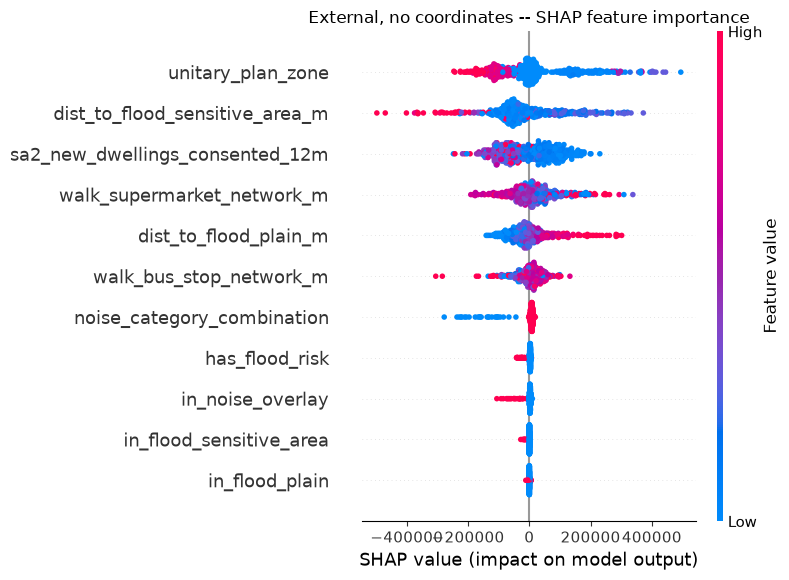

In [15]:
split_point = int(len(df_cv) * 0.8)
train_df, test_df = df_cv.iloc[:split_point], df_cv.iloc[split_point:]

encoder_nc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder_nc.fit(train_df[EXTERNAL_CAT])

X_train_nc = train_df[external_cols_no_coords].copy()
X_test_nc = test_df[external_cols_no_coords].copy()
X_train_nc[EXTERNAL_CAT] = encoder_nc.transform(train_df[EXTERNAL_CAT])
X_test_nc[EXTERNAL_CAT] = encoder_nc.transform(test_df[EXTERNAL_CAT])
for col in EXTERNAL_BOOL:
    X_train_nc[col] = X_train_nc[col].astype(int)
    X_test_nc[col] = X_test_nc[col].astype(int)
X_train_nc, X_test_nc = X_train_nc.astype(float), X_test_nc.astype(float)

nan_cols_nc = [c for c in EXTERNAL_NUM_NC if X_train_nc[c].isna().any() or X_test_nc[c].isna().any()]
medians_nc = X_train_nc[nan_cols_nc].median()
X_train_nc[nan_cols_nc] = X_train_nc[nan_cols_nc].fillna(medians_nc)
X_test_nc[nan_cols_nc] = X_test_nc[nan_cols_nc].fillna(medians_nc)
for col in LOG_COLS:
    if col in X_train_nc.columns:
        X_train_nc[col] = np.log1p(X_train_nc[col])
        X_test_nc[col] = np.log1p(X_test_nc[col])

y_train_nc = train_df["sale_price_gross"].values
p1nc, p99nc = np.quantile(y_train_nc, [0.01, 0.99])
train_keep_nc = (y_train_nc >= p1nc) & (y_train_nc <= p99nc)

nc_model = XGBRegressor(**XGB_PARAMS)
nc_model.fit(X_train_nc[train_keep_nc], y_train_nc[train_keep_nc])

shap_sample_nc = X_test_nc.sample(n=min(500, len(X_test_nc)), random_state=42)
explainer_nc = shap.TreeExplainer(nc_model)
shap_values_nc = explainer_nc.shap_values(shap_sample_nc)

shap.summary_plot(shap_values_nc, shap_sample_nc, max_display=15, show=False)
plt.title("External, no coordinates -- SHAP feature importance")
plt.tight_layout()
plt.show()

In [16]:
mean_abs_shap_nc = pd.Series(np.abs(shap_values_nc).mean(axis=0), index=external_cols_no_coords)
nc_shap_rank = mean_abs_shap_nc.sort_values(ascending=False)
nc_shap_rank_pct = nc_shap_rank / nc_shap_rank.sum() * 100

pd.DataFrame({"mean_abs_shap": nc_shap_rank.round(0), "% of total": nc_shap_rank_pct.round(1)})

,mean_abs_shap,% of total
unitary_plan_zone,94798.0,22.700001
dist_to_flood_sensitive_area_m,87885.0,21.100000
sa2_new_dwellings_consented_12m,75352.0,18.100000
walk_supermarket_network_m,55522.0,13.300000
dist_to_flood_plain_m,48803.0,11.700000
walk_bus_stop_network_m,29280.0,7.000000
noise_category_combination,15011.0,3.600000
has_flood_risk,4626.0,1.100000
in_noise_overlay,4570.0,1.100000
in_flood_sensitive_area,727.0,0.200000


## 9. SHAP for the property-only ("internal") model

The mirror image of sections 7 and 8: no external data at all, only the
10 native structural/property attributes (`baseline_cols`). Same single
80/20 chronological split and 500-row SHAP sample as those sections, for a
direct side-by-side comparison.

In [17]:
split_point = int(len(df_cv) * 0.8)
train_df, test_df = df_cv.iloc[:split_point], df_cv.iloc[split_point:]

encoder_int = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder_int.fit(train_df[BASELINE_CAT])

X_train_int = train_df[baseline_cols].copy()
X_test_int = test_df[baseline_cols].copy()
X_train_int[BASELINE_CAT] = encoder_int.transform(train_df[BASELINE_CAT])
X_test_int[BASELINE_CAT] = encoder_int.transform(test_df[BASELINE_CAT])
X_train_int, X_test_int = X_train_int.astype(float), X_test_int.astype(float)

for col in LOG_COLS:
    if col in X_train_int.columns:
        X_train_int[col] = np.log1p(X_train_int[col])
        X_test_int[col] = np.log1p(X_test_int[col])

y_train_int = train_df["sale_price_gross"].values
p1i, p99i = np.quantile(y_train_int, [0.01, 0.99])
train_keep_i = (y_train_int >= p1i) & (y_train_int <= p99i)

int_model = XGBRegressor(**XGB_PARAMS)
int_model.fit(X_train_int[train_keep_i], y_train_int[train_keep_i])

shap_sample_int = X_test_int.sample(n=min(500, len(X_test_int)), random_state=42)
explainer_int = shap.TreeExplainer(int_model)
shap_values_int = explainer_int.shap_values(shap_sample_int)

print(f"Model trained on {len(baseline_cols)} property-only features, {train_keep_i.sum():,} train rows")

Model trained on 22 property-only features, 46,889 train rows


### 9.1 Summary plot

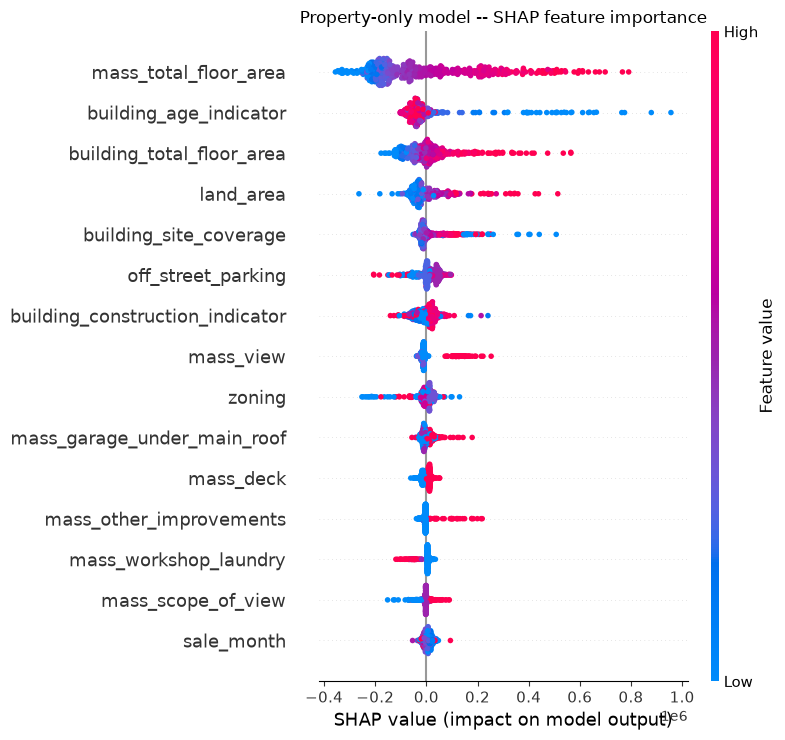

In [18]:
shap.summary_plot(shap_values_int, shap_sample_int, max_display=15, show=False)
plt.title("Property-only model -- SHAP feature importance")
plt.tight_layout()
plt.show()

### 9.2 Ranked table

In [19]:
mean_abs_shap_int = pd.Series(np.abs(shap_values_int).mean(axis=0), index=baseline_cols)
int_shap_rank = mean_abs_shap_int.sort_values(ascending=False)
int_shap_rank_pct = int_shap_rank / int_shap_rank.sum() * 100

pd.DataFrame({"mean_abs_shap": int_shap_rank.round(0), "% of total": int_shap_rank_pct.round(1)})

,mean_abs_shap,% of total
mass_total_floor_area,187076.0,28.700001
building_age_indicator,72579.0,11.100000
building_total_floor_area,67609.0,10.400000
land_area,50109.0,7.700000
building_site_coverage,42525.0,6.500000
off_street_parking,31079.0,4.800000
building_construction_indicator,30353.0,4.600000
mass_view,27866.0,4.300000
zoning,23220.0,3.600000
mass_garage_under_main_roof,15095.0,2.300000


## 10. Combined model: top 10 internal + top 5 external features (no coordinates)

**Top 10 internal** (by SHAP, section 9): `mass_total_floor_area`,
`building_age_indicator`, `building_total_floor_area`, `land_area`,
`building_site_coverage`, `off_street_parking`,
`building_construction_indicator`, `mass_view`, `zoning`,
`mass_garage_under_main_roof`.

**Top 5 external, excluding coordinates** (by SHAP, section 7, skipping
`latitude`/`longitude`): `unitary_plan_zone`,
`dist_to_flood_sensitive_area_m`, `walk_bus_stop_network_m`,
`walk_supermarket_network_m`, `dist_to_flood_plain_m`.

15 features total, none of them raw coordinates. Same 5-fold
`TimeSeriesSplit` for RMSE/MAE/MAPE, then the same single
80/20-split SHAP approach as sections 7-9.


In [20]:
TOP10_INTERNAL = [
    "mass_total_floor_area", "building_age_indicator", "building_total_floor_area",
    "land_area", "building_site_coverage", "off_street_parking",
    "building_construction_indicator", "mass_view", "zoning", "mass_garage_under_main_roof",
]
TOP5_EXTERNAL = [
    "unitary_plan_zone", "dist_to_flood_sensitive_area_m", "walk_bus_stop_network_m",
    "walk_supermarket_network_m", "dist_to_flood_plain_m",
]  # top 5 external by SHAP (section 7), EXCLUDING latitude/longitude
top15_cols = TOP10_INTERNAL + TOP5_EXTERNAL

CAT_TOP15 = [c for c in top15_cols if c in (BASELINE_CAT + EXTERNAL_CAT)]
NUM_TOP15 = [c for c in top15_cols if c in (BASELINE_NUM + EXTERNAL_NUM)]
print(f"{len(top15_cols)} features: {len(CAT_TOP15)} categorical, {len(NUM_TOP15)} numeric")
print("Categorical:", CAT_TOP15)
print("Numeric:", NUM_TOP15)

15 features: 5 categorical, 10 numeric
Categorical: ['building_age_indicator', 'building_construction_indicator', 'mass_view', 'zoning', 'unitary_plan_zone']
Numeric: ['mass_total_floor_area', 'building_total_floor_area', 'land_area', 'building_site_coverage', 'off_street_parking', 'mass_garage_under_main_roof', 'dist_to_flood_sensitive_area_m', 'walk_bus_stop_network_m', 'walk_supermarket_network_m', 'dist_to_flood_plain_m']


### 10.1 5-fold result, compared against every model so far

In [21]:
kf = TimeSeriesSplit(n_splits=5)
fold_rows_15 = []
oof_rows_15 = []

for fold_i, (train_idx, test_idx) in enumerate(kf.split(df_cv), start=1):
    train_df, test_df = df_cv.iloc[train_idx], df_cv.iloc[test_idx]

    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[CAT_TOP15])

    X_train = train_df[top15_cols].copy()
    X_test = test_df[top15_cols].copy()
    X_train[CAT_TOP15] = encoder.transform(train_df[CAT_TOP15])
    X_test[CAT_TOP15] = encoder.transform(test_df[CAT_TOP15])
    X_train, X_test = X_train.astype(float), X_test.astype(float)

    nan_cols = [c for c in NUM_TOP15 if X_train[c].isna().any() or X_test[c].isna().any()]
    medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(medians)

    for col in LOG_COLS:
        if col in X_train.columns:
            X_train[col] = np.log1p(X_train[col])
            X_test[col] = np.log1p(X_test[col])

    y_train, y_test = train_df["sale_price_gross"].values, test_df["sale_price_gross"].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)
    X_train_f, y_train_f = X_train[train_keep], y_train[train_keep]
    X_test_f, y_test_f = X_test[test_keep], y_test[test_keep]
    test_idx_f = test_idx[test_keep]

    model = XGBRegressor(**XGB_PARAMS)
    model.fit(X_train_f, y_train_f)
    pred = model.predict(X_test_f)

    fold_rows_15.append({
        "fold": fold_i, "n_test": len(y_test_f),
        "RMSE": rmse(y_test_f, pred), "MAE": mae(y_test_f, pred), "MAPE": mape(y_test_f, pred),
    })
    oof_rows_15.append(pd.DataFrame({"row_id": test_idx_f, "fold": fold_i, "actual": y_test_f, "pred": pred}))
    print(f"Fold {fold_i}/5: top-15 RMSE=${fold_rows_15[-1]['RMSE']:,.0f}  "
          f"MAE=${fold_rows_15[-1]['MAE']:,.0f}  MAPE={fold_rows_15[-1]['MAPE']:.2f}%")

oof_15 = pd.concat(oof_rows_15, ignore_index=True)
top15_rmse = rmse(oof_15["actual"], oof_15["pred"])
top15_mae = mae(oof_15["actual"], oof_15["pred"])
top15_mape = mape(oof_15["actual"], oof_15["pred"])
print(f"\nOut-of-fold rows: {len(oof_15):,}")

Fold 1/5: top-15 RMSE=$328,818  MAE=$209,094  MAPE=18.19%
Fold 2/5: top-15 RMSE=$301,790  MAE=$197,961  MAPE=17.08%
Fold 3/5: top-15 RMSE=$306,733  MAE=$199,617  MAPE=17.83%
Fold 4/5: top-15 RMSE=$294,481  MAE=$193,568  MAPE=16.91%
Fold 5/5: top-15 RMSE=$280,767  MAE=$186,419  MAPE=16.45%

Out-of-fold rows: 48,848


In [22]:
comparison_15 = pd.DataFrame([
    {"model": "Property only (10 features)", "RMSE": REF_BASELINE_RMSE, "MAE": REF_BASELINE_MAE, "MAPE": REF_BASELINE_MAPE},
    {"model": "External, no coordinates (11 features)", "RMSE": nc_rmse, "MAE": nc_mae, "MAPE": nc_mape},
    {"model": "External, with coordinates (13 features)", "RMSE": ext_rmse, "MAE": ext_mae, "MAPE": ext_mape},
    {"model": "Top 10 internal + top 5 external, no coordinates (15 features, this section)", "RMSE": top15_rmse, "MAE": top15_mae, "MAPE": top15_mape},
    {"model": "Property + external, all 36 features (final.ipynb augmented)", "RMSE": REF_AUGMENTED_RMSE, "MAE": REF_AUGMENTED_MAE, "MAPE": REF_AUGMENTED_MAPE},
]).set_index("model")
comparison_15.round(2)

,RMSE,MAE,MAPE
model,,,
Property only (10 features),317631.16,208318.50,18.17
"External, no coordinates (11 features)",473633.04,331755.33,31.18
"External, with coordinates (13 features)",384260.94,258780.87,23.98
"Top 10 internal + top 5 external, no coordinates (15 features, this section)",302939.41,197334.30,17.29
"Property + external, all 36 features (final.ipynb augmented)",214529.56,131243.38,11.31


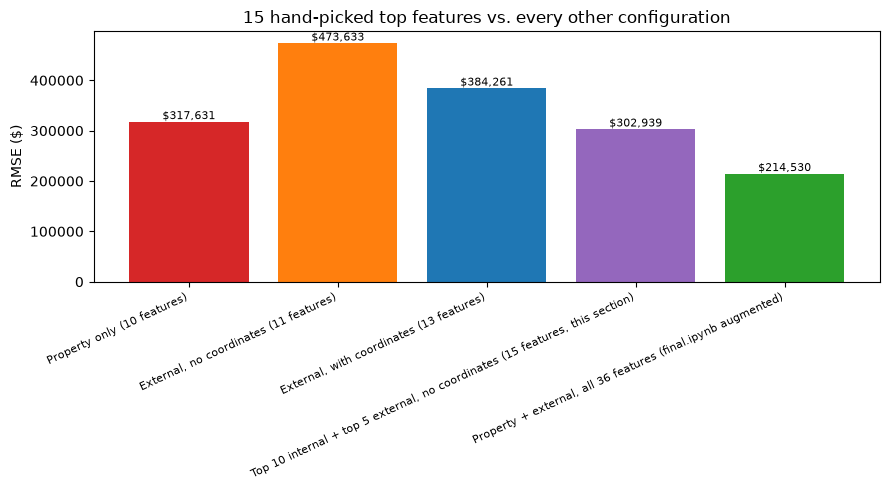

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
colors15 = ["tab:red", "tab:orange", "tab:blue", "tab:purple", "tab:green"]
bars = ax.bar(range(len(comparison_15)), comparison_15["RMSE"], color=colors15)
for bar, v in zip(bars, comparison_15["RMSE"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"${v:,.0f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(comparison_15)))
ax.set_xticklabels(comparison_15.index, rotation=25, ha="right", fontsize=8)
ax.set_ylabel("RMSE ($)")
ax.set_title("15 hand-picked top features vs. every other configuration")
plt.tight_layout()
plt.show()

### 10.2 SHAP for the combined 15-feature model

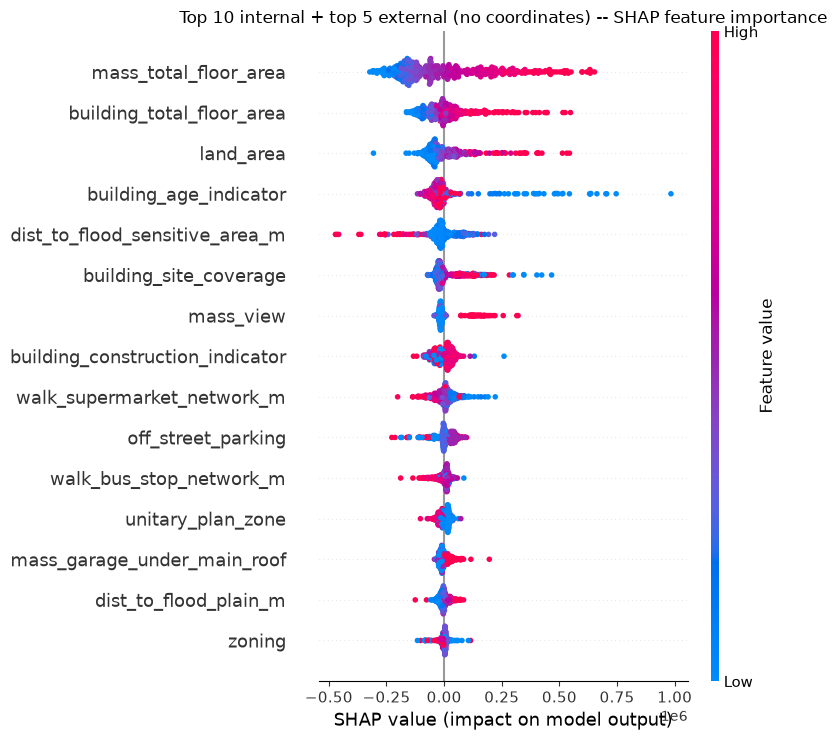

In [24]:
split_point = int(len(df_cv) * 0.8)
train_df, test_df = df_cv.iloc[:split_point], df_cv.iloc[split_point:]

encoder_15 = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder_15.fit(train_df[CAT_TOP15])

X_train_15 = train_df[top15_cols].copy()
X_test_15 = test_df[top15_cols].copy()
X_train_15[CAT_TOP15] = encoder_15.transform(train_df[CAT_TOP15])
X_test_15[CAT_TOP15] = encoder_15.transform(test_df[CAT_TOP15])
X_train_15, X_test_15 = X_train_15.astype(float), X_test_15.astype(float)

nan_cols_15 = [c for c in NUM_TOP15 if X_train_15[c].isna().any() or X_test_15[c].isna().any()]
medians_15 = X_train_15[nan_cols_15].median()
X_train_15[nan_cols_15] = X_train_15[nan_cols_15].fillna(medians_15)
X_test_15[nan_cols_15] = X_test_15[nan_cols_15].fillna(medians_15)
for col in LOG_COLS:
    if col in X_train_15.columns:
        X_train_15[col] = np.log1p(X_train_15[col])
        X_test_15[col] = np.log1p(X_test_15[col])

y_train_15 = train_df["sale_price_gross"].values
p1_15, p99_15 = np.quantile(y_train_15, [0.01, 0.99])
train_keep_15 = (y_train_15 >= p1_15) & (y_train_15 <= p99_15)

model_15 = XGBRegressor(**XGB_PARAMS)
model_15.fit(X_train_15[train_keep_15], y_train_15[train_keep_15])

shap_sample_15 = X_test_15.sample(n=min(500, len(X_test_15)), random_state=42)
explainer_15 = shap.TreeExplainer(model_15)
shap_values_15 = explainer_15.shap_values(shap_sample_15)

shap.summary_plot(shap_values_15, shap_sample_15, max_display=15, show=False)
plt.title("Top 10 internal + top 5 external (no coordinates) -- SHAP feature importance")
plt.tight_layout()
plt.show()

In [25]:
mean_abs_shap_15 = pd.Series(np.abs(shap_values_15).mean(axis=0), index=top15_cols)
shap_rank_15 = mean_abs_shap_15.sort_values(ascending=False)
shap_rank_15_pct = shap_rank_15 / shap_rank_15.sum() * 100

source_15 = {c: ("internal" if c in TOP10_INTERNAL else "external") for c in top15_cols}
pd.DataFrame({
    "mean_abs_shap": shap_rank_15.round(0), "% of total": shap_rank_15_pct.round(1),
    "source": [source_15[c] for c in shap_rank_15.index],
})

,mean_abs_shap,% of total,source
mass_total_floor_area,170002.0,26.0,internal
building_total_floor_area,69754.0,10.7,internal
land_area,62649.0,9.6,internal
building_age_indicator,60134.0,9.2,internal
dist_to_flood_sensitive_area_m,47235.0,7.2,external
building_site_coverage,46395.0,7.1,internal
mass_view,31334.0,4.8,internal
building_construction_indicator,29669.0,4.5,internal
walk_supermarket_network_m,29156.0,4.5,external
off_street_parking,29141.0,4.5,internal


## 11. Everything above, repeated with Random Forest

Sections 6-10 all used XGBoost. This repeats all five feature-set
configurations with `RandomForestRegressor` (same config used throughout
this project's earlier notebooks -- `n_estimators=150, max_depth=18,
min_samples_leaf=2`), to check whether the findings hold with a different
model family or are specific to XGBoost.

All five configurations, explicitly redefined here so this section is
self-contained (not dependent on variable state left over from earlier
cells):

1. Property only (10 features)
2. External, with coordinates (13 features)
3. External, no coordinates (11 features)
4. Top 10 internal + top 5 external, with coordinates (15 features)
5. Top 10 internal + top 5 external, no coordinates (15 features)

In [26]:
from sklearn.ensemble import RandomForestRegressor

RF_PARAMS = dict(n_estimators=150, max_depth=18, min_samples_leaf=2, n_jobs=-1, random_state=42)

TOP5_EXTERNAL_COORDS = ["latitude", "longitude", "unitary_plan_zone", "dist_to_flood_sensitive_area_m", "walk_bus_stop_network_m"]
TOP5_EXTERNAL_NO_COORDS = ["unitary_plan_zone", "dist_to_flood_sensitive_area_m", "walk_bus_stop_network_m",
                           "walk_supermarket_network_m", "dist_to_flood_plain_m"]

RF_CONFIGS = {
    "Property only": {"cols": baseline_cols, "cat": BASELINE_CAT, "num": BASELINE_NUM},
    "External, with coordinates": {"cols": external_cols, "cat": EXTERNAL_CAT, "num": EXTERNAL_NUM, "bool": EXTERNAL_BOOL},
    "External, no coordinates": {"cols": external_cols_no_coords, "cat": EXTERNAL_CAT, "num": EXTERNAL_NUM_NC, "bool": EXTERNAL_BOOL},
    "Top 15, with coordinates": {
        "cols": TOP10_INTERNAL + TOP5_EXTERNAL_COORDS,
        "cat": [c for c in (TOP10_INTERNAL + TOP5_EXTERNAL_COORDS) if c in (BASELINE_CAT + EXTERNAL_CAT)],
        "num": [c for c in (TOP10_INTERNAL + TOP5_EXTERNAL_COORDS) if c in (BASELINE_NUM + EXTERNAL_NUM)],
    },
    "Top 15, no coordinates": {
        "cols": TOP10_INTERNAL + TOP5_EXTERNAL_NO_COORDS,
        "cat": [c for c in (TOP10_INTERNAL + TOP5_EXTERNAL_NO_COORDS) if c in (BASELINE_CAT + EXTERNAL_CAT)],
        "num": [c for c in (TOP10_INTERNAL + TOP5_EXTERNAL_NO_COORDS) if c in (BASELINE_NUM + EXTERNAL_NUM)],
    },
}
for name, cfg in RF_CONFIGS.items():
    cfg.setdefault("bool", [])
    print(f"{name}: {len(cfg['cols'])} features")

Property only: 22 features
External, with coordinates: 13 features
External, no coordinates: 11 features
Top 15, with coordinates: 15 features
Top 15, no coordinates: 15 features


### 11.1 5-fold Random Forest results for all five configurations

In [27]:
def run_rf_cv(cols, cat_cols, num_cols, bool_cols):
    kf_local = TimeSeriesSplit(n_splits=5)
    oof_parts = []
    for train_idx, test_idx in kf_local.split(df_cv):
        train_df, test_df = df_cv.iloc[train_idx], df_cv.iloc[test_idx]

        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
        enc.fit(train_df[cat_cols])

        X_train = train_df[cols].copy()
        X_test = test_df[cols].copy()
        if cat_cols:
            X_train[cat_cols] = enc.transform(train_df[cat_cols])
            X_test[cat_cols] = enc.transform(test_df[cat_cols])
        for col in bool_cols:
            X_train[col] = X_train[col].astype(int)
            X_test[col] = X_test[col].astype(int)
        X_train, X_test = X_train.astype(float), X_test.astype(float)

        nan_cols = [c for c in num_cols if X_train[c].isna().any() or X_test[c].isna().any()]
        if nan_cols:
            medians = X_train[nan_cols].median()
            X_train[nan_cols] = X_train[nan_cols].fillna(medians)
            X_test[nan_cols] = X_test[nan_cols].fillna(medians)

        for col in LOG_COLS:
            if col in X_train.columns:
                X_train[col] = np.log1p(X_train[col])
                X_test[col] = np.log1p(X_test[col])

        y_train, y_test = train_df["sale_price_gross"].values, test_df["sale_price_gross"].values
        p1, p99 = np.quantile(y_train, [0.01, 0.99])
        train_keep = (y_train >= p1) & (y_train <= p99)
        test_keep = (y_test >= p1) & (y_test <= p99)
        X_train_f, y_train_f = X_train[train_keep], y_train[train_keep]
        X_test_f, y_test_f = X_test[test_keep], y_test[test_keep]

        m = RandomForestRegressor(**RF_PARAMS)
        m.fit(X_train_f, y_train_f)
        pred = m.predict(X_test_f)
        oof_parts.append(pd.DataFrame({"actual": y_test_f, "pred": pred}))

    oof_local = pd.concat(oof_parts, ignore_index=True)
    return rmse(oof_local["actual"], oof_local["pred"]), mae(oof_local["actual"], oof_local["pred"]), mape(oof_local["actual"], oof_local["pred"])


rf_results = {}
for name, cfg in RF_CONFIGS.items():
    r, m_, p = run_rf_cv(cfg["cols"], cfg["cat"], cfg["num"], cfg["bool"])
    rf_results[name] = {"RMSE": r, "MAE": m_, "MAPE": p}
    print(f"{name:35s}  RMSE=${r:,.0f}  MAE=${m_:,.0f}  MAPE={p:.2f}%")

Property only                        RMSE=$328,020  MAE=$215,465  MAPE=18.97%
External, with coordinates           RMSE=$372,004  MAE=$243,698  MAPE=22.30%
External, no coordinates             RMSE=$465,143  MAE=$323,149  MAPE=30.46%
Top 15, with coordinates             RMSE=$234,632  MAE=$138,311  MAPE=11.75%
Top 15, no coordinates               RMSE=$317,115  MAE=$204,288  MAPE=17.82%


### 11.2 Random Forest vs. XGBoost, side by side

In [28]:
xgb_reference = {
    "Property only": {"RMSE": REF_BASELINE_RMSE, "MAE": REF_BASELINE_MAE, "MAPE": REF_BASELINE_MAPE},
    "External, with coordinates": {"RMSE": ext_rmse, "MAE": ext_mae, "MAPE": ext_mape},
    "External, no coordinates": {"RMSE": nc_rmse, "MAE": nc_mae, "MAPE": nc_mape},
    "Top 15, with coordinates": {"RMSE": top15_rmse, "MAE": top15_mae, "MAPE": top15_mape},
}

rows = []
for name in RF_CONFIGS:
    row = {"config": name, "RF_RMSE": rf_results[name]["RMSE"], "RF_MAE": rf_results[name]["MAE"], "RF_MAPE": rf_results[name]["MAPE"]}
    if name in xgb_reference:
        row["XGB_RMSE"] = xgb_reference[name]["RMSE"]
        row["XGB_MAE"] = xgb_reference[name]["MAE"]
        row["XGB_MAPE"] = xgb_reference[name]["MAPE"]
    else:
        row["XGB_RMSE"] = np.nan
        row["XGB_MAE"] = np.nan
        row["XGB_MAPE"] = np.nan
    rows.append(row)

rf_vs_xgb = pd.DataFrame(rows).set_index("config")
rf_vs_xgb.round(2)

,RF_RMSE,RF_MAE,RF_MAPE,XGB_RMSE,XGB_MAE,XGB_MAPE
config,,,,,,
Property only,328020.30,215464.76,18.97,317631.16,208318.50,18.17
"External, with coordinates",372004.50,243698.29,22.30,384260.94,258780.87,23.98
"External, no coordinates",465142.52,323148.76,30.46,473633.04,331755.33,31.18
"Top 15, with coordinates",234631.80,138310.93,11.75,302939.41,197334.30,17.29
"Top 15, no coordinates",317115.29,204288.31,17.82,NaN,NaN,NaN


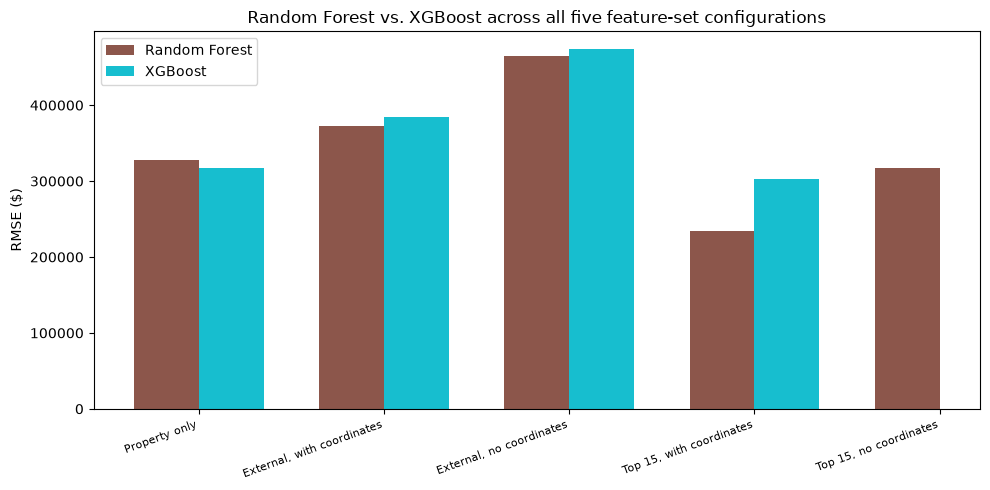

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(rf_vs_xgb))
width = 0.35
ax.bar(x - width / 2, rf_vs_xgb["RF_RMSE"], width, label="Random Forest", color="tab:brown")
ax.bar(x + width / 2, rf_vs_xgb["XGB_RMSE"], width, label="XGBoost", color="tab:cyan")
ax.set_xticks(x)
ax.set_xticklabels(rf_vs_xgb.index, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("RMSE ($)")
ax.set_title("Random Forest vs. XGBoost across all five feature-set configurations")
ax.legend()
plt.tight_layout()
plt.show()

### 11.3 SHAP for each Random Forest model (single 80/20 split, 500-row sample)

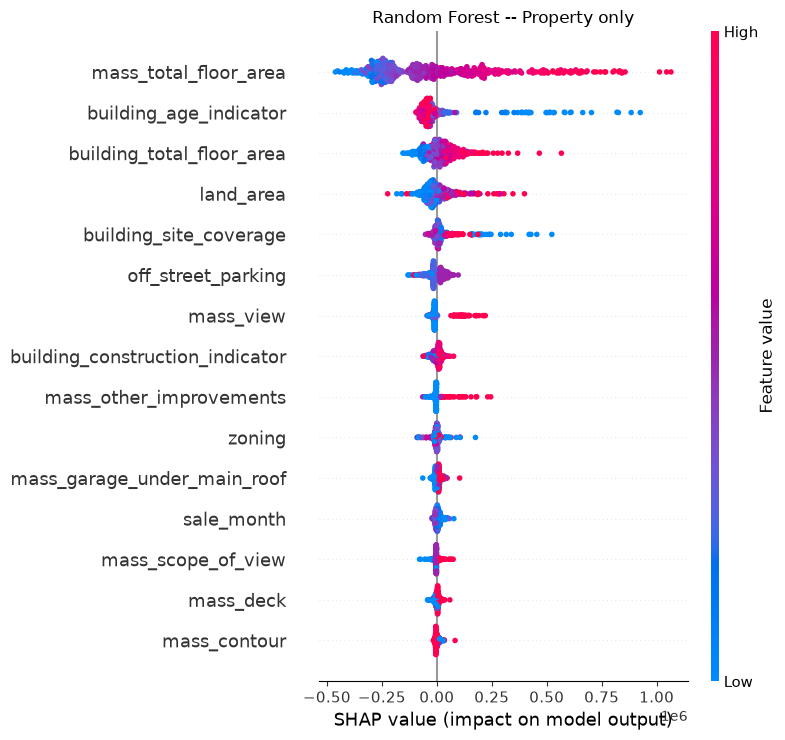

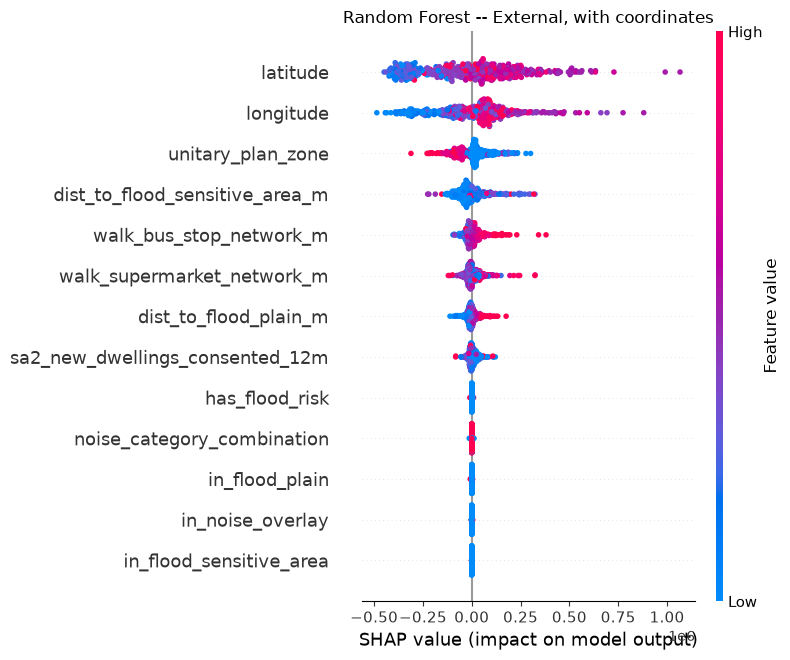

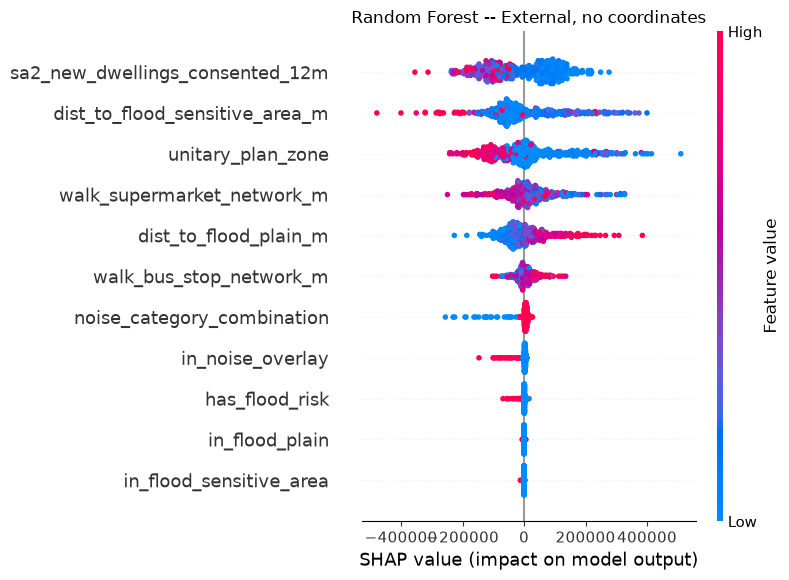

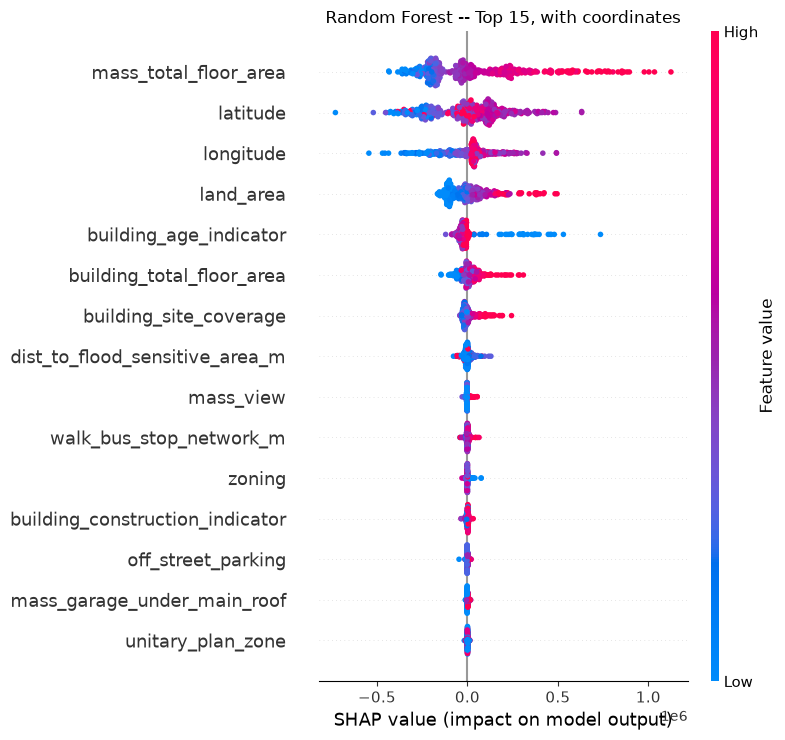

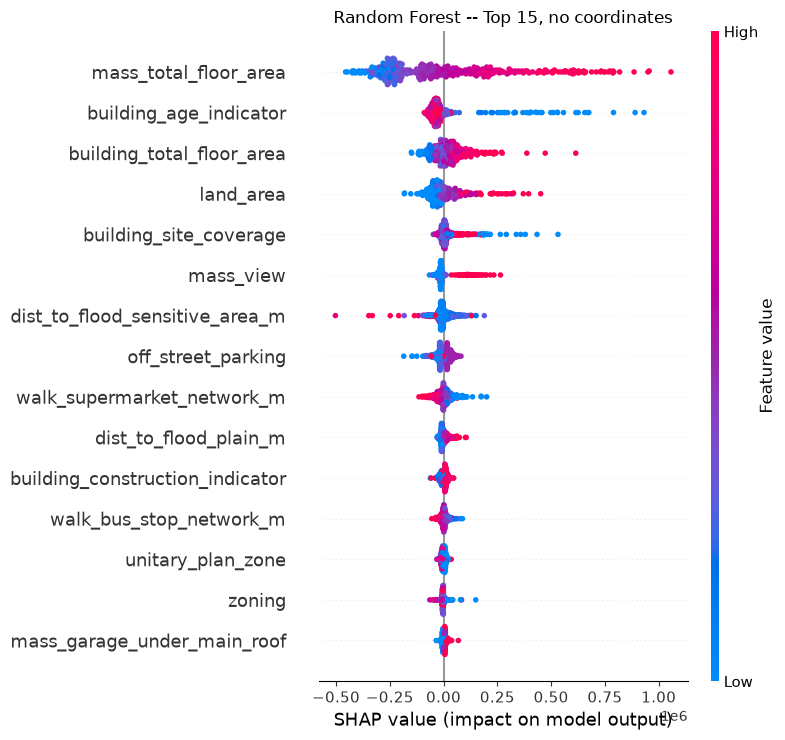

In [30]:
split_point = int(len(df_cv) * 0.8)
train_df_all, test_df_all = df_cv.iloc[:split_point], df_cv.iloc[split_point:]

rf_shap_rankings = {}

for name, cfg in RF_CONFIGS.items():
    cols, cat_cols, num_cols, bool_cols = cfg["cols"], cfg["cat"], cfg["num"], cfg["bool"]

    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    enc.fit(train_df_all[cat_cols])

    X_train = train_df_all[cols].copy()
    X_test = test_df_all[cols].copy()
    if cat_cols:
        X_train[cat_cols] = enc.transform(train_df_all[cat_cols])
        X_test[cat_cols] = enc.transform(test_df_all[cat_cols])
    for col in bool_cols:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train, X_test = X_train.astype(float), X_test.astype(float)

    nan_cols = [c for c in num_cols if X_train[c].isna().any() or X_test[c].isna().any()]
    if nan_cols:
        medians = X_train[nan_cols].median()
        X_train[nan_cols] = X_train[nan_cols].fillna(medians)
        X_test[nan_cols] = X_test[nan_cols].fillna(medians)
    for col in LOG_COLS:
        if col in X_train.columns:
            X_train[col] = np.log1p(X_train[col])
            X_test[col] = np.log1p(X_test[col])

    y_train = train_df_all["sale_price_gross"].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)

    rf_model = RandomForestRegressor(**RF_PARAMS)
    rf_model.fit(X_train[train_keep], y_train[train_keep])

    shap_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)
    explainer = shap.TreeExplainer(rf_model)
    sv = explainer.shap_values(shap_sample)

    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=cols).sort_values(ascending=False)
    rf_shap_rankings[name] = mean_abs

    shap.summary_plot(sv, shap_sample, max_display=15, show=False)
    plt.title(f"Random Forest -- {name}")
    plt.tight_layout()
    plt.show()

### 11.4 Top-5 SHAP features per configuration (Random Forest)

In [31]:
for name, ranking in rf_shap_rankings.items():
    pct = ranking / ranking.sum() * 100
    print(f"\n{name}:")
    for feat, val in ranking.head(5).items():
        print(f"  {feat:35s} {val:>10,.0f}  ({pct[feat]:.1f}%)")


Property only:
  mass_total_floor_area                  238,874  (40.9%)
  building_age_indicator                  72,700  (12.4%)
  building_total_floor_area               55,509  (9.5%)
  land_area                               43,737  (7.5%)
  building_site_coverage                  31,529  (5.4%)

External, with coordinates:
  latitude                               201,939  (36.9%)
  longitude                              143,384  (26.2%)
  unitary_plan_zone                       59,976  (11.0%)
  dist_to_flood_sensitive_area_m          50,404  (9.2%)
  walk_bus_stop_network_m                 29,751  (5.4%)

External, no coordinates:
  sa2_new_dwellings_consented_12m         95,881  (22.6%)
  dist_to_flood_sensitive_area_m          90,340  (21.3%)
  unitary_plan_zone                       87,603  (20.6%)
  walk_supermarket_network_m              54,762  (12.9%)
  dist_to_flood_plain_m                   54,099  (12.7%)

Top 15, with coordinates:
  mass_total_floor_area             

### 11.5 What changed (or didn't) compared to XGBoost

Fill in after running:

- Do the RMSE rankings across the 5 configurations stay in the same order
  as XGBoost (property only < external-no-coords < external-with-coords <
  top-15-no-coords < top-15-with-coords <~ full augmented)?
- Does Random Forest get closer to or farther from XGBoost's accuracy in
  each configuration?
- Does the SHAP ranking within each configuration broadly agree between
  the two model families, or does Random Forest lean on different
  features (e.g. tree-structure differences changing how correlated
  features like the three distance-to-flood columns get credited)?